In [1]:
from src.baseline.qwen3 import init_model
from pathlib import Path
from typing import List, Dict, Any
import statistics
import json


def read_jsonl_file(path: Path) -> List[Dict[str, Any]]:
    with path.open('r', encoding='utf-8') as f:
        return [json.loads(line) for line in f if line.strip()]


tokenizer, model = init_model("Qwen/Qwen3-0.6B")

d:\GitHub\text2sql_distillation_draft\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 311/311 [00:03<00:00, 98.76it/s] 
Some parameters are on the meta device because they were offloaded to the cpu and disk.


In [25]:
# benchmark_dir = Path("benchmarks") / "spider_data" / "format_data"
# benchmark_dir = Path("benchmarks_2") / "spider_syn" / "format_data"
# benchmark_dir = Path("benchmarks_2") / "spider_realistic" / "format_data"
benchmark_dir = Path("benchmarks_2") / "spider_dk" / "format_data"

# raw_train_data = read_jsonl_file(benchmark_dir / "train.jsonl")
# raw_dev_data = read_jsonl_file(benchmark_dir / "dev.jsonl")
raw_test_data = read_jsonl_file(benchmark_dir / "test.jsonl")



In [26]:
def get_prompt_text(tokenizer, system_prompt: str, user_prompt: str, enable_thinking: bool = False) -> str:
    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": user_prompt},
    ]
    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=enable_thinking,
    )
    return text


def token_length(tokenizer, text: str, model_device=None) -> int:
    inputs = tokenizer(text, return_tensors="pt")
    if model_device is not None:
        inputs = inputs.to(model_device)
    return inputs["input_ids"].shape[-1]


def summarize_lengths(lengths: List[int]) -> Dict[str, Any]:
    if not lengths:
        return {}

    lengths_sorted = sorted(lengths)
    n = len(lengths_sorted)

    def percentile(p: float) -> float:
        if n == 1:
            return lengths_sorted[0]
        idx = (n - 1) * p
        low = int(idx)
        high = min(low + 1, n - 1)
        frac = idx - low
        return lengths_sorted[low] * (1 - frac) + lengths_sorted[high] * frac

    return {
        "count": n,
        "min": min(lengths_sorted),
        "max": max(lengths_sorted),
        "mean": sum(lengths_sorted) / n,
        "median": statistics.median(lengths_sorted),
        "p50": percentile(0.50),
        "p90": percentile(0.90),
        "p95": percentile(0.95),
        "p99": percentile(0.99),
    }



In [27]:
from tqdm.auto import tqdm


def analyze_dataset_token_lengths(
    dataset: List[Dict[str, Any]],
    tokenizer,
    enable_thinking: bool = False,
):
    prompt_lengths = []
    prompt_plus_response_lengths = []
    response_only_lengths = []

    results = []

    for i, item in tqdm(enumerate(dataset), total=len(dataset)):
        prompt_text = get_prompt_text(
            tokenizer=tokenizer,
            system_prompt=item["system_prompt"],
            user_prompt=item["user_prompt"],
            enable_thinking=enable_thinking,
        )
        response_text = item["response"]

        prompt_len = token_length(tokenizer, prompt_text)
        full_text = prompt_text + response_text
        full_len = token_length(tokenizer, full_text)
        response_len = full_len - prompt_len

        prompt_lengths.append(prompt_len)
        prompt_plus_response_lengths.append(full_len)
        response_only_lengths.append(response_len)

        results.append({
            "idx": i,
            "prompt_len": prompt_len,
            "prompt_plus_response_len": full_len,
            "response_len_only": response_len,
        })

    summary = {
        "prompt_only": summarize_lengths(prompt_lengths),
        "response_only": summarize_lengths(response_only_lengths),
        "prompt_plus_response": summarize_lengths(prompt_plus_response_lengths),
    }

    return results, summary



In [28]:
results, summary = analyze_dataset_token_lengths(raw_test_data, tokenizer, enable_thinking=False)
# results, summary = analyze_dataset_token_lengths(raw_dev_data, tokenizer, enable_thinking=False)
# results, summary = analyze_dataset_token_lengths(raw_train_data, tokenizer, enable_thinking=False)



100%|██████████| 535/535 [00:01<00:00, 293.61it/s]


In [29]:
summary


{'prompt_only': {'count': 535,
  'min': 295,
  'max': 643,
  'mean': 386.3588785046729,
  'median': 372,
  'p50': 372.0,
  'p90': 510.0,
  'p95': 515.3,
  'p99': 522.9799999999999},
 'response_only': {'count': 535,
  'min': 10,
  'max': 129,
  'mean': 37.88785046728972,
  'median': 29,
  'p50': 29.0,
  'p90': 67.60000000000002,
  'p95': 82.0,
  'p99': 119.65999999999997},
 'prompt_plus_response': {'count': 535,
  'min': 305,
  'max': 663,
  'mean': 424.2467289719626,
  'median': 408,
  'p50': 408.0,
  'p90': 536.0,
  'p95': 562.3,
  'p99': 596.9599999999998}}

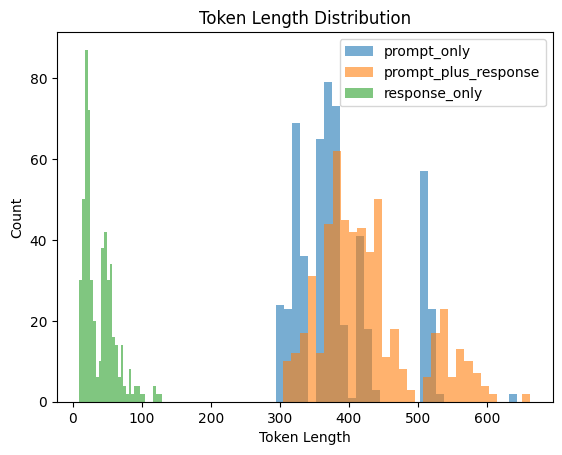

In [30]:
import matplotlib.pyplot as plt

prompt_lens = [x["prompt_len"] for x in results]
full_lens = [x["prompt_plus_response_len"] for x in results]
response_lens = [x["response_len_only"] for x in results]

plt.figure()
plt.hist(prompt_lens, bins=30, alpha=0.6, label="prompt_only")
plt.hist(full_lens, bins=30, alpha=0.6, label="prompt_plus_response")
plt.hist(response_lens, bins=30, alpha=0.6, label="response_only")

plt.xlabel("Token Length")
plt.ylabel("Count")
plt.title("Token Length Distribution")
plt.legend()

plt.show()



In [31]:
sorted(results, key=lambda x: x["prompt_plus_response_len"], reverse=True)[:10]


[{'idx': 381,
  'prompt_len': 643,
  'prompt_plus_response_len': 663,
  'response_len_only': 20},
 {'idx': 382,
  'prompt_len': 643,
  'prompt_plus_response_len': 663,
  'response_len_only': 20},
 {'idx': 427,
  'prompt_len': 529,
  'prompt_plus_response_len': 615,
  'response_len_only': 86},
 {'idx': 428,
  'prompt_len': 525,
  'prompt_plus_response_len': 611,
  'response_len_only': 86},
 {'idx': 445,
  'prompt_len': 521,
  'prompt_plus_response_len': 599,
  'response_len_only': 78},
 {'idx': 446,
  'prompt_len': 521,
  'prompt_plus_response_len': 599,
  'response_len_only': 78},
 {'idx': 442,
  'prompt_len': 521,
  'prompt_plus_response_len': 593,
  'response_len_only': 72},
 {'idx': 441,
  'prompt_len': 520,
  'prompt_plus_response_len': 592,
  'response_len_only': 72},
 {'idx': 459,
  'prompt_len': 516,
  'prompt_plus_response_len': 586,
  'response_len_only': 70},
 {'idx': 503,
  'prompt_len': 516,
  'prompt_plus_response_len': 586,
  'response_len_only': 70}]